In [72]:
import numpy as np
import funcoes as fn
import matplotlib.pyplot as plt

# Unidades

## Comprimento

um = 1e-6
nm = 1e-9

## frequência 

GHz = 1e9
THz = 1e12

# Constantes

pi = np.pi
c = 3e8 # m/s
u0 = 4*pi*1e-7
e0 = 1/(36*pi) * 1e-9

lambda0 = 1.55*um
f0 = c/lambda0

k0 = 2*pi/lambda0

In [73]:
# Dados da fibra

a = 4.1*um
n1 = 1.4505
n2 = 1.4447

In [74]:
def p(b):
    p2 = (n1*k0)**2 - b**2
    return np.sqrt(p2)
def q(b):
    q2 = b**2 - (n2*k0)**2
    return np.sqrt(q2)

def F(b, m):
    pa = p(b)*a
    qa = q(b)*a

    J = fn.J(pa, m, 80)
    dJ = fn.DJ(pa, m, 80)
    K = fn.K(qa, m, 80)
    dK = fn.DK(qa, m, 80)

    P1 = dJ/(pa*J) + dK/(qa*K)
    P2 = dJ/(pa*J) + ((n2/n1)**2)*dK/(qa*K)

    return P1*P2 - (m**2)*(1/(pa**2) + 1/(qa**2))*(1/(pa**2) + ((n2/n1)**2)*1/(qa**2))

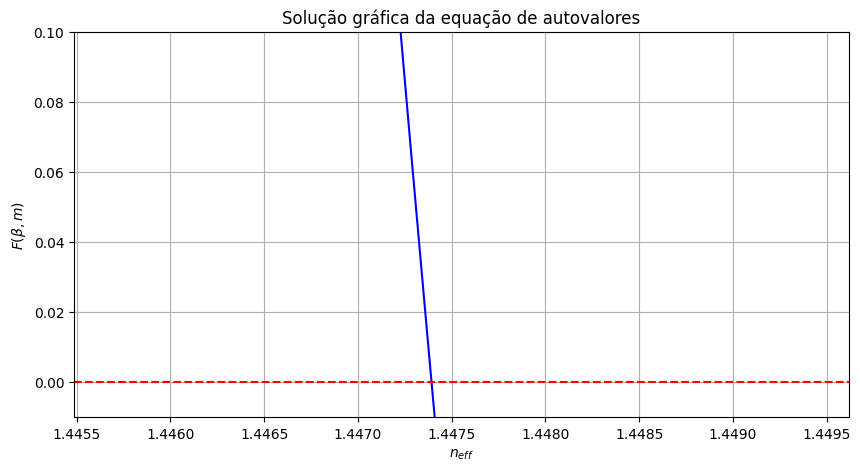

In [75]:
b_array = np.linspace(1.4448, 1.4504, 2001)*k0

m = 1

F_array = F(b_array, m)

# Identifica valores muito elevados
mask = np.abs(F_array) < 2

plt.figure(figsize=(10,5))
plt.plot(b_array[mask]/k0, F_array[mask], color = 'blue')
plt.grid(True)
plt.ylim([-0.01, 0.1])
plt.axhline(0, color = 'red', linestyle = '--')
plt.xlabel(r'$n_{eff}$')
plt.ylabel(r'$F(\beta, m)$')
plt.title('Solução gráfica da equação de autovalores')
plt.show()

In [76]:
# Algoritmo para encontrar as raízes

def localizar_raizes(x, y, e=1e-5):
    raizes = []
    if len(x) != len(y):
        raise ValueError('os vetores x e y devem ter o mesmo tamanho.')
    if len(x) == 0:
        raise ValueError('Os vetores devem conter elementos.')
    N = len(x)

    possiveis_raizes = []
    for k in range(0,N-1,1):
        if y[k] == 0:
            raizes.append(x[k])
            possiveis_raizes = []
            continue
        elif y[k]*y[k+1] < 0:
            raiz = x[k] - y[k]*(x[k+1]-x[k])/(y[k+1]-y[k])
            raizes.append(raiz)
            possiveis_raizes = []
            continue
        elif abs(y[k]) < e:
            possiveis_raizes.append(k)
            if abs(y[k+1]) > e:
                i = np.argmin(np.abs(y[possiveis_raizes]))
                raiz = x[possiveis_raizes[i]]
                if not raiz in raizes: 
                    raizes.append(raiz)
                possiveis_raizes = []
    if np.abs(y[-1]) < e:
        raizes.append(x[-1])
    return np.array(raizes) 

In [77]:
raizes = localizar_raizes(b_array[mask], F_array[mask])
N = len(raizes)
for k in range(1,N+1,1):
    print('Indice efetivo do %dº modo encontrado para m = %d: %.4f' %(k,m,raizes[k-1]/k0))

Indice efetivo do 1º modo encontrado para m = 1: 1.4474
